# 01. Data Diagnosis

## Goal

원본 스내치 영상에서 `videos.csv` Manifest를 안전하게 생성하거나 불러오고, 다음 분석 단계 전에 기본 데이터 상태를 확인합니다.

## Setup

이 노트북은 프로젝트 루트 또는 `notebooks/` 디렉터리에서 실행할 수 있습니다. 재사용 로직은 `metadata.py`와 `video.py`에서 가져옵니다.

In [1]:
from pathlib import Path
import os

import cv2
import matplotlib.pyplot as plt
import pandas as pd

from snatch_analysis.config import B00_VIDEO_ID
from snatch_analysis.metadata import (
    build_evaluation_video_split,
    save_video_manifest,
    set_has_plate_labels,
    set_split_roles_by_person,
    set_visible_body_side_labels,
    write_video_manifest,
)
from snatch_analysis.phases import prepare_phase_annotations
from snatch_analysis.plate import (
    build_pilot_ground_truth_template,
    sample_phase_frames,
    save_pilot_ground_truth,
    validate_pilot_ground_truth,
)
from snatch_analysis.video import (
    iter_video_frames,
    read_video_frame,
    read_video_properties,
)


PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "pyproject.toml").exists():
    raise FileNotFoundError("프로젝트 루트 또는 notebooks 디렉터리에서 실행해 주세요.")

os.chdir(PROJECT_ROOT)
print(f"Project root: {PROJECT_ROOT}")

Project root: /Users/gyeongsulim/Documents/WL_project


## Steps

### 1. 경로와 재생성 여부 설정

`REBUILD_MANIFEST=False`가 기본값입니다. 기존 CSV가 있으면 그대로 불러오므로 이후 직접 기록할 `has_plate`, `camera_motion` 값이 유지됩니다. 원본 영상이 추가되었거나 자동 메타데이터를 처음부터 다시 만들 때만 `True`로 바꾸세요.

In [2]:
VIDEO_DIR = Path("data/raw/videos")
MANIFEST_PATH = Path("data/metadata/videos.csv")
REBUILD_MANIFEST = False

### 2. Manifest 생성 또는 불러오기

CSV가 없거나 `REBUILD_MANIFEST=True`이면 `write_video_manifest()`가 영상을 읽어 새 CSV를 만듭니다. 그 외에는 기존 CSV를 불러옵니다.

In [3]:
if REBUILD_MANIFEST or not MANIFEST_PATH.exists():
    manifest = write_video_manifest(VIDEO_DIR, MANIFEST_PATH)
    manifest_action = "생성"
else:
    manifest = pd.read_csv(MANIFEST_PATH)
    manifest_action = "기존 파일 불러오기"

print(f"Manifest: {manifest_action}")
print(f"Path: {MANIFEST_PATH}")

Manifest: 기존 파일 불러오기
Path: data/metadata/videos.csv


### 2-1. 촬영 신체면 수동 라벨링

선수의 왼쪽 신체면이 보이면 `left`, 오른쪽이면 `right`, 검토했지만 사선·가림으로 판단하기 어려우면 `uncertain`을 입력합니다. 아직 검토하지 않은 영상은 `unknown`으로 유지합니다. 화면에서 선수가 바라보는 방향과 혼동하지 마세요.

In [4]:
VISIBLE_BODY_SIDE_LABELS = {
    # "b00_sn_f_01": "left",
}

In [5]:
manifest = set_visible_body_side_labels(
    manifest, VISIBLE_BODY_SIDE_LABELS
)
save_video_manifest(manifest, MANIFEST_PATH)

side_label_counts = (
    manifest["visible_body_side"]
    .value_counts(dropna=False)
    .rename_axis("visible_body_side")
    .to_frame("video_count")
)
print(f"촬영 신체면 라벨 저장: {MANIFEST_PATH}")
display(side_label_counts)
manifest.loc[
    manifest["visible_body_side"] == "unknown",
    ["video_id", "visible_body_side"],
].head(10)

촬영 신체면 라벨 저장: data/metadata/videos.csv


,video_count
visible_body_side,
unknown,53
left,1


,video_id,visible_body_side
0,a01_sn_f_01,unknown
1,a02_sn_f_01,unknown
2,a03_sn_f_01,unknown
3,a04_sn_f_01,unknown
4,a04_sn_h_02,unknown
5,a05_sn_f_01,unknown
6,a06_sn_h_01,unknown
7,a07_sn_f_01,unknown
8,a07_sn_h_02,unknown
9,a08_sn_f_01,unknown


## Checks

원본 MP4 개수와 Manifest 행 수, 중복 ID, 영상 읽기 상태를 확인합니다. 문제가 있으면 다음 단계로 넘어가지 않고 여기서 원인을 확인합니다.

In [6]:
video_count = len(list(VIDEO_DIR.glob("*.mp4")))
if video_count == 0:
    raise FileNotFoundError(f"MP4 파일이 없습니다: {VIDEO_DIR}")
if len(manifest) != video_count:
    raise ValueError(f"영상 {video_count}개와 Manifest {len(manifest)}행이 일치하지 않습니다.")
if manifest["video_id"].duplicated().any():
    raise ValueError("중복 video_id가 있습니다.")

diagnosis_summary = pd.Series(
    {
        "video_files": video_count,
        "manifest_rows": len(manifest),
        "unique_people": manifest["person_id"].nunique(),
        "read_ok": int((manifest["read_status"] == "ok").sum()),
        "read_error": int((manifest["read_status"] != "ok").sum()),
    },
    name="count",
)
diagnosis_summary.to_frame()

,count
video_files,54
manifest_rows,54
unique_people,24
read_ok,54
read_error,0


### 3. Manifest 일부 확인

출력이 너무 길어지지 않도록 앞의 5개 행만 확인합니다.

In [7]:
manifest.head(5)

,video_id,filename,path,group,person_id,lift,completion,rep_index,file_size_bytes,fps,frame_count,duration_sec,width,height,read_status,has_plate,camera_motion,visible_body_side
0,a01_sn_f_01,a01_sn_f_01.mp4,data/raw/videos/a01_sn_f_01.mp4,A,a01,sn,f,1,636095,24.003523,109,4.541,720,1280,ok,unknown,unknown,unknown
1,a02_sn_f_01,a02_sn_f_01.mp4,data/raw/videos/a02_sn_f_01.mp4,A,a02,sn,f,1,803632,24.059882,135,5.611,720,1280,ok,unknown,unknown,unknown
2,a03_sn_f_01,a03_sn_f_01.mp4,data/raw/videos/a03_sn_f_01.mp4,A,a03,sn,f,1,758632,24.175412,129,5.336,720,1280,ok,unknown,unknown,unknown
3,a04_sn_f_01,a04_sn_f_01.mp4,data/raw/videos/a04_sn_f_01.mp4,A,a04,sn,f,1,747629,24.072753,135,5.608,720,1280,ok,unknown,unknown,unknown
4,a04_sn_h_02,a04_sn_h_02.mp4,data/raw/videos/a04_sn_h_02.mp4,A,a04,sn,h,2,372080,24.370755,61,2.503,720,1280,ok,unknown,unknown,unknown


## U2. 영상 프레임과 시간 기준 확인

여기서는 Pose와 원판 분석이 함께 사용할 기준을 눈으로 확인합니다. 영상의 실제 FPS를 사용해 `timestamp_sec = frame_index / fps`로 계산하며, generator가 한 번에 한 프레임만 전달합니다. 표에는 이미지 전체가 아니라 작은 프레임 메타데이터만 저장합니다.

### 4. 실험값 설정

`VIDEO_ID`로 영상을 바꾸고, `PREVIEW_FRAME_INDEX`로 보고 싶은 프레임을 선택하세요. `SAMPLE_EVERY_N_FRAMES`는 시간표에 표시할 간격이며 영상 처리 간격을 뜻하지 않습니다.

In [8]:
VIDEO_ID = B00_VIDEO_ID
PREVIEW_FRAME_INDEX = 0
SAMPLE_EVERY_N_FRAMES = 60

### 5. 프레임을 순서대로 읽고 기준 검사

모든 프레임을 `list`로 보관하지 않습니다. 현재 프레임에서 인덱스, 시간, 크기만 확인한 뒤 다음 프레임으로 넘어갑니다.

In [9]:
if SAMPLE_EVERY_N_FRAMES <= 0:
    raise ValueError("SAMPLE_EVERY_N_FRAMES는 1 이상이어야 합니다.")

selected_rows = manifest.loc[manifest["video_id"] == VIDEO_ID]
if selected_rows.empty:
    available_ids = ", ".join(manifest["video_id"].head(5))
    raise ValueError(f"Manifest에 VIDEO_ID={VIDEO_ID!r}가 없습니다. 예시: {available_ids}")

selected_video = selected_rows.iloc[0]
video_path = Path(selected_video["path"])
expected_frame_count = int(selected_video["frame_count"])
video_properties = read_video_properties(video_path)

frame_samples = []
decoded_frame_count = 0
first_frame_index = None
last_frame_index = None
last_timestamp_sec = None
frame_shape = None

for frame_index, timestamp_sec, frame in iter_video_frames(
    video_path,
    expected_frame_count=expected_frame_count,
):
    if first_frame_index is None:
        first_frame_index = frame_index
        frame_shape = frame.shape
    last_frame_index = frame_index
    last_timestamp_sec = timestamp_sec
    decoded_frame_count += 1

    if frame_index % SAMPLE_EVERY_N_FRAMES == 0:
        frame_samples.append(
            {
                "frame_index": frame_index,
                "timestamp_sec": round(timestamp_sec, 6),
                "frame_shape": str(frame.shape),
            }
        )

if frame_samples[-1]["frame_index"] != last_frame_index:
    frame_samples.append(
        {
            "frame_index": last_frame_index,
            "timestamp_sec": round(last_timestamp_sec, 6),
            "frame_shape": str(frame_shape),
        }
    )

### 6. 영상 입력 계약 요약

`PASS`가 나오면 Manifest와 실제 디코딩 결과가 같은 프레임·시간 기준을 사용한다는 뜻입니다.

In [10]:
contract_checks = {
    "starts_at_zero": first_frame_index == 0,
    "count_matches_manifest": decoded_frame_count == expected_frame_count,
    "last_index_matches_count": last_frame_index == decoded_frame_count - 1,
    "fps_matches_manifest": abs(
        float(video_properties["fps"]) - float(selected_video["fps"])
    ) < 1e-6,
    "shape_matches_manifest": frame_shape
    == (int(selected_video["height"]), int(selected_video["width"]), 3),
}
contract_status = "PASS" if all(contract_checks.values()) else "FAIL"

video_contract_summary = pd.Series(
    {
        "video_id": VIDEO_ID,
        "FPS": video_properties["fps"],
        "프레임 범위": f"{first_frame_index} ~ {last_frame_index}",
        "Manifest 프레임 수": expected_frame_count,
        "실제 디코딩 프레임 수": decoded_frame_count,
        "프레임 크기": str(frame_shape),
        "색상 순서": "BGR",
        "읽기 방식": "generator streaming",
        "계약 검사": contract_status,
    },
    name="value",
)
video_contract_summary.to_frame()

,value
video_id,b00_sn_f_01
FPS,60.142068
프레임 범위,0 ~ 253
Manifest 프레임 수,254
실제 디코딩 프레임 수,254
프레임 크기,"(1488, 836, 3)"
색상 순서,BGR
읽기 방식,generator streaming
계약 검사,PASS


In [11]:
failed_checks = [name for name, passed in contract_checks.items() if not passed]
if failed_checks:
    raise RuntimeError(f"영상 입력 계약 실패: {', '.join(failed_checks)}")

validated_video_id = VIDEO_ID
validated_video_path = video_path

pd.Series(contract_checks, name="passed").to_frame()

,passed
starts_at_zero,True
count_matches_manifest,True
last_index_matches_count,True
fps_matches_manifest,True
shape_matches_manifest,True


### 7. 프레임과 시간 표본 확인

첫 프레임, 설정한 간격의 프레임과 마지막 프레임을 확인합니다. 각 시간은 실제 FPS를 사용해 계산됩니다.

In [12]:
pd.DataFrame(frame_samples)

,frame_index,timestamp_sec,frame_shape
0,0,0.000000,"(1488, 836, 3)"
1,60,0.997638,"(1488, 836, 3)"
2,120,1.995276,"(1488, 836, 3)"
3,180,2.992913,"(1488, 836, 3)"
4,240,3.990551,"(1488, 836, 3)"
5,253,4.206706,"(1488, 836, 3)"


### 8. 선택 프레임 확인

OpenCV는 BGR 순서로 읽으므로 화면에 표시할 때만 RGB로 바꿉니다. 원본 프레임의 좌우 방향은 변경하지 않습니다.

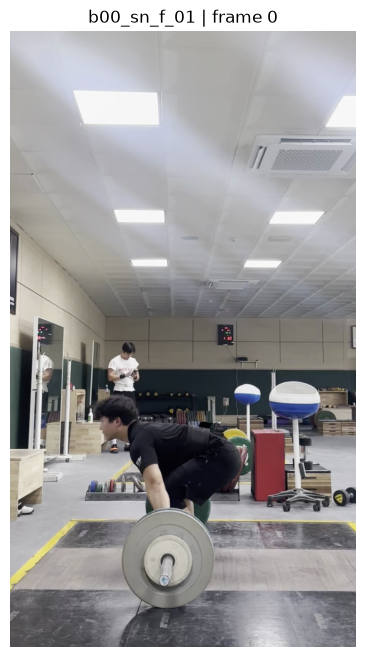

In [13]:
if VIDEO_ID != validated_video_id:
    raise RuntimeError(
        "VIDEO_ID를 변경했다면 5~6단계 셀을 다시 실행해 영상 계약을 확인하세요."
    )

preview_frame = read_video_frame(validated_video_path, PREVIEW_FRAME_INDEX)
preview_rgb = cv2.cvtColor(preview_frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 8))
plt.imshow(preview_rgb)
plt.title(f"{validated_video_id} | frame {PREVIEW_FRAME_INDEX}")
plt.axis("off")
plt.show()

### 9. 관찰 기록

- 확인한 `VIDEO_ID`:
- 변경한 실험값:
- 프레임·시간 기준에서 발견한 점:
- 좌우 방향 또는 영상 읽기 문제:

## U9. 사람 단위 평가 기준선 만들기

B00 개발 결과와 분리된 평가 영상을 고정합니다. 모델 결과를 보기 전에 사람별 역할, A/B/C model-selection 영상, phase event와 수동 bbox를 저장합니다. 이 구역의 CSV는 `data/` 아래에 저장되어 Git에는 올라가지 않습니다.

### 10. 평가 후보 인물 확인

같은 사람의 반복 영상은 하나의 역할에만 들어가야 합니다. 먼저 인물별 영상 수와 `f/h` 구성을 확인합니다. U12 전 model-selection pilot은 Recovery까지 있는 `f` 영상을 선택합니다.

In [14]:
u9_inventory_columns = {"group", "person_id", "video_id", "completion"}
if u9_inventory_columns.issubset(manifest.columns):
    u9_person_inventory = (
        manifest.groupby(["group", "person_id"], as_index=False)
        .agg(
            video_count=("video_id", "size"),
            completions=("completion", lambda values: ",".join(sorted(set(values)))),
        )
        .sort_values(["group", "person_id"])
    )
    display(u9_person_inventory)
else:
    u9_person_inventory = pd.DataFrame()
    print("U9 후보 표 생략: 테스트용 최소 manifest에는 인물 열이 없습니다.")

,group,person_id,video_count,completions
0,A,a01,1,f
1,A,a02,1,f
2,A,a03,1,f
3,A,a04,2,"f,h"
4,A,a05,1,f
5,A,a06,1,h
6,A,a07,2,"f,h"
7,A,a08,1,f
8,B,b00,1,f
9,B,b01,3,f


### 11. 사람 역할과 평가 영상 설정

평가에 쓰지 않는 사람은 자동으로 `training_development`가 됩니다. 아래 딕셔너리에는 평가 인물만 입력하세요. `model_selection_pilot`은 A/B/C 한 명씩, `rule_development`와 `rule_blind`는 서로 다른 사람이어야 합니다. `U9_SELECTED_VIDEO_IDS`에는 평가 인물마다 영상 하나를 넣습니다.

In [15]:
U9_EVALUATION_PERSON_ROLES = {
    # "a01": "model_selection_pilot",
    # "b01": "model_selection_pilot",
    # "c01": "model_selection_pilot",
    # "a02": "rule_development",
    # "a03": "rule_blind",
}
U9_SELECTED_VIDEO_IDS = [
    # "a01_sn_f_01",
    # "b01_sn_f_01",
    # "c01_sn_f_01",
]
U9_VIDEO_LABELS = {
    # "a01_sn_f_01": {"has_plate": "yes", "visible_body_side": "left"},
}
U9_EVENT_FRAMES = {
    # "a01_sn_f_01": {
    #     "bar_off_floor": 0, "knee_pass": 0, "max_extension": 0,
    #     "catch_stable": 0, "recovery_stable": 0,
    # },
}
U9_ANNOTATOR = ""
OVERWRITE_U9_PHASE_EVENTS = False
RUN_U9_MANUAL_BBOX_LABELING = False
OVERWRITE_U9_GROUND_TRUTH = False

In [16]:
EVALUATION_SPLIT_PATH = Path("data/splits/evaluation_videos.csv")
u9_split_ready = bool(
    U9_EVALUATION_PERSON_ROLES
    and U9_SELECTED_VIDEO_IDS
    and U9_VIDEO_LABELS
)

if u9_split_ready:
    required_evaluation_roles = {
        "model_selection_pilot", "rule_development", "rule_blind"
    }
    configured_roles = set(U9_EVALUATION_PERSON_ROLES.values())
    missing_roles = sorted(required_evaluation_roles - configured_roles)
    if missing_roles:
        raise ValueError("U9 평가 역할이 비어 있습니다: " + ", ".join(missing_roles))

    roles_by_person = {
        str(person_id): "training_development"
        for person_id in manifest["person_id"].astype(str).unique()
    }
    core_training_people = set(
        manifest.loc[
            manifest["video_id"] == B00_VIDEO_ID, "person_id"
        ].astype(str)
    )
    leaked_training_people = sorted(
        core_training_people & set(U9_EVALUATION_PERSON_ROLES)
    )
    if leaked_training_people:
        raise ValueError(
            "Core training person은 평가 역할에 넣을 수 없습니다: "
            + ", ".join(leaked_training_people)
        )
    roles_by_person.update(U9_EVALUATION_PERSON_ROLES)
    visible_labels = {
        video_id: labels["visible_body_side"]
        for video_id, labels in U9_VIDEO_LABELS.items()
    }
    plate_labels = {
        video_id: labels["has_plate"]
        for video_id, labels in U9_VIDEO_LABELS.items()
    }
    manifest = set_split_roles_by_person(manifest, roles_by_person)
    manifest = set_visible_body_side_labels(manifest, visible_labels)
    manifest = set_has_plate_labels(manifest, plate_labels)
    evaluation_split = build_evaluation_video_split(
        manifest, U9_SELECTED_VIDEO_IDS
    )
    save_video_manifest(manifest, MANIFEST_PATH)
    save_video_manifest(evaluation_split, EVALUATION_SPLIT_PATH)
    display(evaluation_split)
else:
    evaluation_split = pd.DataFrame()
    print("U9 split 저장 대기: 역할·평가 영상·수동 메타데이터를 입력하세요.")

U9 split 저장 대기: 역할·평가 영상·수동 메타데이터를 입력하세요.


### 12. Model-selection pilot 이벤트와 10프레임 표본

A/B/C pilot의 실제 다섯 이벤트를 영상을 천천히 보며 입력합니다. 기존 수동 이벤트가 있으면 재사용하며, 덮어쓰려면 `OVERWRITE_U9_PHASE_EVENTS=True`로 바꿉니다. 저장한 phase에서 영상당 10프레임을 고르게 선택합니다.

In [17]:
PHASE_ANNOTATION_PATH = Path("data/annotations/phase_events.csv")
u9_sample_tables = []
u9_samples_ready = False

if u9_split_ready:
    pilot_rows = evaluation_split.loc[
        evaluation_split["split_role"] == "model_selection_pilot"
    ]
    existing_event_ids = set()
    if PHASE_ANNOTATION_PATH.exists():
        existing_event_ids = set(
            pd.read_csv(PHASE_ANNOTATION_PATH)["video_id"].astype(str)
        )
    required_event_ids = set(pilot_rows["video_id"].astype(str))
    missing_event_ids = sorted(
        required_event_ids - existing_event_ids - set(U9_EVENT_FRAMES)
    )
    if missing_event_ids:
        print("U9 이벤트 입력 대기: " + ", ".join(missing_event_ids))
    else:
        for row in pilot_rows.itertuples(index=False):
            _, phase_by_frame, action = prepare_phase_annotations(
                video_id=row.video_id,
                event_frames=U9_EVENT_FRAMES.get(row.video_id, {}),
                frame_count=int(row.frame_count),
                annotation_path=PHASE_ANNOTATION_PATH,
                artifact_directory=Path("artifacts/u9_pilot") / row.video_id,
                annotator=U9_ANNOTATOR,
                overwrite=OVERWRITE_U9_PHASE_EVENTS,
            )
            sampled = sample_phase_frames(phase_by_frame, sample_count=10)
            sampled["phase_action"] = action
            u9_sample_tables.append(sampled)
        u9_samples = pd.concat(u9_sample_tables, ignore_index=True)
        u9_samples_ready = True
        display(u9_samples)
else:
    print("U9 phase 표본 대기: 먼저 evaluation split을 저장하세요.")

if not u9_samples_ready:
    u9_samples = pd.DataFrame()

U9 phase 표본 대기: 먼저 evaluation split을 저장하세요.


### 13. 수동 정답 프레임 확인

모델 결과를 실행하기 전에 30개 프레임을 확인합니다. `sampling_phase`는 표본을 나눈 구간이고 `analysis_phase`는 실제 frame phase입니다.

In [18]:
u9_review_frames = {}

if u9_samples_ready:
    video_metadata = evaluation_split.set_index("video_id")
    for video_id, rows in u9_samples.groupby("video_id"):
        target_indices = set(rows["frame_index"].astype(int))
        metadata = video_metadata.loc[video_id]
        for frame_index, _, frame in iter_video_frames(
            Path(metadata["path"]), expected_frame_count=int(metadata["frame_count"])
        ):
            if frame_index in target_indices:
                u9_review_frames[(video_id, frame_index)] = frame
        missing_frames = target_indices - {
            frame_index
            for cached_video_id, frame_index in u9_review_frames
            if cached_video_id == video_id
        }
        if missing_frames:
            raise RuntimeError(
                f"U9 frame을 읽지 못했습니다: {video_id} {sorted(missing_frames)}"
            )
    contact_columns = 5
    contact_rows = (len(u9_samples) + contact_columns - 1) // contact_columns
    figure, axes = plt.subplots(
        contact_rows, contact_columns, figsize=(15, 3 * contact_rows)
    )
    axes = axes.ravel()
    for axis, row in zip(axes, u9_samples.itertuples(index=False)):
        frame = u9_review_frames[(row.video_id, int(row.frame_index))]
        axis.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        axis.set_title(
            f"{row.video_id} | {row.frame_index} | {row.sampling_phase}",
            fontsize=8,
        )
        axis.axis("off")
    for axis in axes[len(u9_samples):]:
        axis.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("U9 contact sheet 대기: 이벤트를 입력해 표본을 만드세요.")

U9 contact sheet 대기: 이벤트를 입력해 표본을 만드세요.


### 14. 원판과 주동작자 bbox 수동 라벨링

프레임을 확인한 다음 `RUN_U9_MANUAL_BBOX_LABELING=True`로 바꿉니다. 원판이 있는 영상은 카메라 쪽 주동작 원판을 먼저, 그다음 주동작자 전체를 선택합니다. 거울·배경 사람과 배경 원판은 선택하지 않습니다. ROI 창에서 `c`로 취소한 값은 좌표를 만들지 않고 N/A 사유로 저장됩니다.

In [19]:
U9_GROUND_TRUTH_PATH = Path("data/annotations/pilot_frame_ground_truth.csv")
u9_ground_truth = pd.DataFrame()

if U9_GROUND_TRUTH_PATH.exists() and not OVERWRITE_U9_GROUND_TRUTH:
    if not u9_samples_ready:
        raise ValueError(
            "기존 U9 정답을 검증하려면 현재 split과 event를 먼저 입력하세요."
        )
    u9_ground_truth = validate_pilot_ground_truth(
        pd.read_csv(U9_GROUND_TRUTH_PATH), evaluation_split
    )
    expected_keys = set(
        u9_samples[["video_id", "frame_index"]].itertuples(
            index=False, name=None
        )
    )
    actual_keys = set(
        u9_ground_truth[["video_id", "frame_index"]].itertuples(
            index=False, name=None
        )
    )
    if actual_keys != expected_keys:
        raise ValueError(
            "현재 표본과 기존 U9 정답 frame이 다릅니다. "
            "다시 라벨링하려면 OVERWRITE_U9_GROUND_TRUTH=True로 바꾸세요."
        )
    print(f"검증된 기존 U9 수동 정답 불러오기: {U9_GROUND_TRUTH_PATH}")
elif u9_samples_ready and RUN_U9_MANUAL_BBOX_LABELING:
    u9_ground_truth = build_pilot_ground_truth_template(
        u9_samples, evaluation_split
    )
    for row_index, row in u9_ground_truth.iterrows():
        frame = u9_review_frames[(row["video_id"], int(row["frame_index"]))].copy()
        reasons = [] if not row["na_reason"] else [str(row["na_reason"])]
        if row["plate_present"] == "yes":
            plate_window = f"plate | {row['video_id']} | {row['frame_index']}"
            plate_bbox = cv2.selectROI(plate_window, frame, False, False)
            cv2.destroyWindow(plate_window)
            if plate_bbox[2] and plate_bbox[3]:
                u9_ground_truth.loc[row_index, [
                    "plate_bbox_x", "plate_bbox_y",
                    "plate_bbox_width", "plate_bbox_height",
                ]] = plate_bbox
            else:
                reasons.append("plate_label_cancelled")

        lifter_window = f"lifter | {row['video_id']} | {row['frame_index']}"
        lifter_bbox = cv2.selectROI(lifter_window, frame, False, False)
        cv2.destroyWindow(lifter_window)
        if lifter_bbox[2] and lifter_bbox[3]:
            u9_ground_truth.loc[row_index, [
                "lifter_bbox_x", "lifter_bbox_y",
                "lifter_bbox_width", "lifter_bbox_height",
            ]] = lifter_bbox
        else:
            reasons.append("lifter_label_cancelled")
        u9_ground_truth.at[row_index, "annotator"] = U9_ANNOTATOR
        u9_ground_truth.at[row_index, "na_reason"] = ";".join(reasons)
    cv2.destroyAllWindows()
    save_pilot_ground_truth(
        u9_ground_truth, evaluation_split, U9_GROUND_TRUTH_PATH
    )
    print(f"U9 수동 정답 저장: {U9_GROUND_TRUTH_PATH}")
else:
    print("U9 bbox 저장 대기: 표본 확인 후 RUN_U9_MANUAL_BBOX_LABELING=True")

U9 bbox 저장 대기: 표본 확인 후 RUN_U9_MANUAL_BBOX_LABELING=True


In [20]:
if not u9_ground_truth.empty:
    u9_ground_truth_summary = pd.Series(
        {
            "videos": u9_ground_truth["video_id"].nunique(),
            "frames": len(u9_ground_truth),
            "plate_bbox_labeled": int(u9_ground_truth["plate_bbox_width"].notna().sum()),
            "lifter_bbox_labeled": int(u9_ground_truth["lifter_bbox_width"].notna().sum()),
            "na_rows": int(u9_ground_truth["na_reason"].fillna("").ne("").sum()),
        },
        name="count",
    )
    display(u9_ground_truth_summary.to_frame())
else:
    print("U9 상태: split·event·bbox 수동 입력이 아직 완료되지 않았습니다.")

U9 상태: split·event·bbox 수동 입력이 아직 완료되지 않았습니다.


## Next Steps

U9의 `evaluation_videos.csv`, 세 pilot의 phase event와 `pilot_frame_ground_truth.csv`를 직접 확인한 뒤 현재 YOLOv8n Pose·plate 기준선을 실행합니다. 수동 정답을 만들기 전에는 candidate 모델 결과를 열지 않습니다.